# Image Classification using CNN

I will work with the Colorectal-histology dataset, which consists of a collection of textures in histological images of human colorectal cancer. It contains 5000 histological RGB images of 150 * 150 px. These images can be classified into 8 categories: tumor, stroma, complex, lympho, debris, mucosa, adipose, empty.

This dataset is part of Tensorflow datasets. **TensorFlow Datasets (TFDS)**.


More info regarding the dataset: https://zenodo.org/record/53169#.XGZemKwzbmG
On TFDS: https://www.tensorflow.org/datasets/catalog/colorectal_histology

In [3]:
!pip install importlib-resources

In [4]:
import tensorflow_datasets as tfds
import tensorflow as tf
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

### Loading and exploring the dataset

In [5]:
#Load colorectal histology
dataset_name = 'colorectal_histology'
dataset, info = tfds.load(dataset_name, split='train', with_info=True, as_supervised=True)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/colorectal_histology/incomplete.QXX1ND_2.0.0/colorectal_histology-train.tf…

Dataset colorectal_histology downloaded and prepared to /root/tensorflow_datasets/colorectal_histology/2.0.0. Subsequent calls will reuse this data.


In [21]:
#Labels
class_labels = info.features["label"].names
print(f'Class labels: {class_labels}')

#Size of the dataset
num_images = info.splits['train'].num_examples
print(f"Total images: {num_images}")

Class labels: ['tumor', 'stroma', 'complex', 'lympho', 'debris', 'mucosa', 'adipose', 'empty']
Total images: 5000


In [17]:
from sklearn.model_selection import train_test_split

#Split into train (70%), test (20%), validation (10%)

X = []
y = []

for image, label in dataset.as_numpy_iterator():
    X.append(image)
    y.append(label)

X = np.array(X)
y = np.array(y)

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1) #We extract 20% of the data for test
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.125, random_state=1) #We extract 12'5% of the data (10% of the original size) for validation

print(f"Shape of training set (x): {x_train.shape}")
print(f"Shape of training set (y): {y_train.shape}")
print(f"Shape of validation set (x): {x_val.shape}")
print(f"Shape of validation set (y): {y_val.shape}")
print(f"Shape of test set (x): {x_test.shape}")
print(f"Shape of test set (y): {y_test.shape}")

Shape of training set (x): (3500, 150, 150, 3)
Shape of training set (y): (3500,)
Shape of validation set (x): (500, 150, 150, 3)
Shape of validation set (y): (500,)
Shape of test set (x): (1000, 150, 150, 3)
Shape of test set (y): (1000,)


In [18]:
#Shape of the images
print(f'Image shape: {x_train[0].shape}')
print(f'Image shape: {x_test[0].shape}')

Image shape: (150, 150, 3)
Image shape: (150, 150, 3)


In [19]:
#Observation distribution per class
_, y_train_counts = np.unique(y_train, return_counts=True) #y_train counts contain the count number for ach class

for label, count in zip(class_labels, y_train_counts):
  print(f'Class: {label}, count: {count}')

Class: tumor, count: 439
Class: stroma, count: 442
Class: complex, count: 449
Class: lympho, count: 442
Class: debris, count: 422
Class: mucosa, count: 448
Class: adipose, count: 431
Class: empty, count: 427


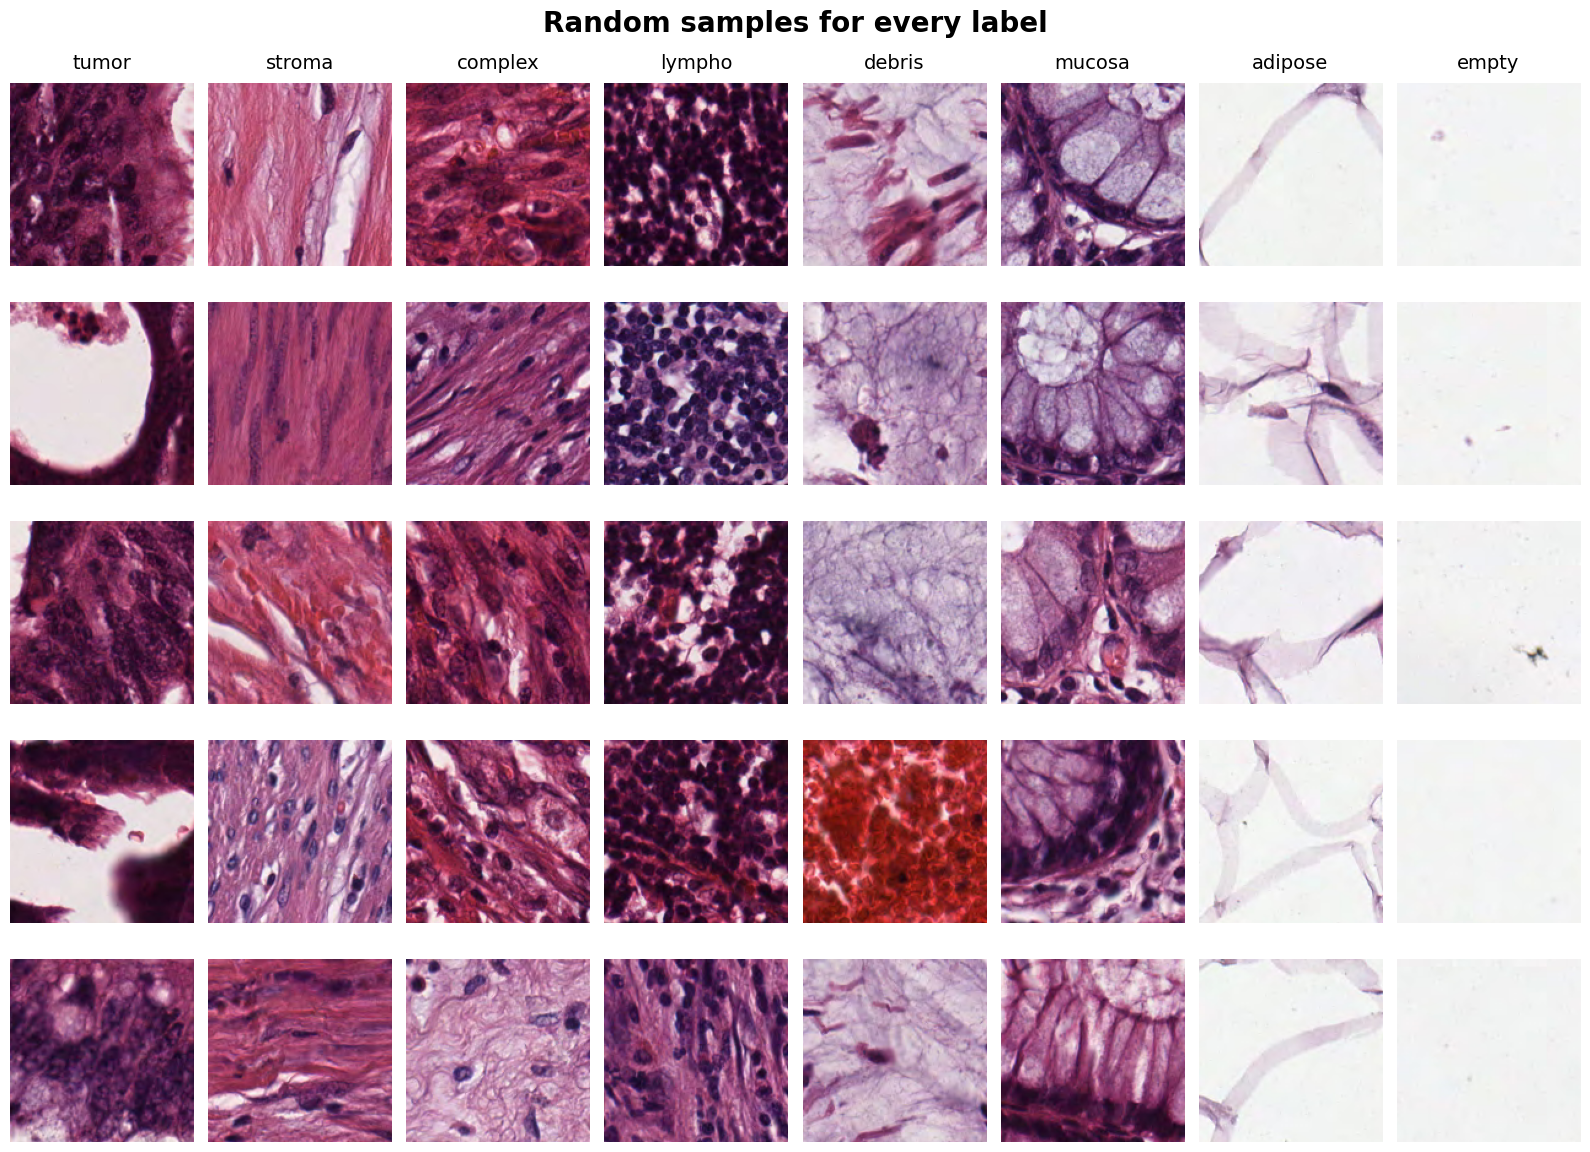

In [20]:
#Visualize the data

names = {i:lab for i,lab in enumerate(class_labels)}
images = {i:[] for i in names.keys()}

for label in images.keys():
  while len(images[label]) < 5: #we repeat the loop until the currect label gets 5 images
    i = random.randrange(0,len(y_train)) #We pick a radom index for y_train
    if y_train[i] == label:
      images[label].append(x_train[i]) #we append the image on x_train using the index of y_train

#Make the graph
fig, axes = plt.subplots(5,8, figsize=(16,12))

fig.suptitle('Random samples for every label', fontsize=20, fontweight='bold')

for label in images.keys():
  for num in range(5):
    axes[num,label].imshow(images[label][num])
    axes[num, label].axis('off')
    if num == 0:
      axes[num, label].set_title(names[label], fontsize=14, pad=10)

fig.subplots_adjust(top=0.92)
plt.tight_layout()
plt.show()

In [22]:
#Convert labels into one-hot encoded form
from tensorflow.keras.utils import to_categorical

print(y_train[1])
y_train = to_categorical(y_train,num_classes=8)
print(y_train[1])
y_val = to_categorical(y_val,num_classes=8)
y_test = to_categorical(y_test,num_classes=8)

7
[0. 0. 0. 0. 0. 0. 0. 1.]


In [23]:
#Preprocess the images to ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

print(x_train.min(), x_train.max())
x_train = preprocess_input(x_train.astype("float32"))
x_val = preprocess_input(x_val.astype("float32"))
x_test = preprocess_input(x_test.astype("float32"))
print(x_train.min(), x_train.max())

0 255
-121.68 151.061


### Data Augmentation

I'll increase artifically the diversity and size of the trainig and validation dataset and validation set by applying various transformations to the original data.

In [26]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(rotation_range=20, width_shift_range=0.1, height_shift_range=0.1, horizontal_flip=True, fill_mode="nearest")
x_train_gen = train_datagen.flow(x_train, y_train)

In [27]:
test_datagen = ImageDataGenerator()
x_val_gen = test_datagen.flow(x_val, y_val, batch_size = 32, shuffle = False)

### Building the model

In [29]:
from keras.backend import clear_session
clear_session()

In [30]:
from keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.models import Sequential

#Load the Resnet50 model
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(150, 150, 3))
base_model.trainable = False

#Building the rest of the model
model = Sequential()
model.add(base_model)
model.add(GlobalAveragePooling2D())
model.add(Dense(128, activation='relu', kernel_initializer='he_uniform'))
model.add(Dropout(0.5))
model.add(Dense(8, activation='softmax'))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 5, 5, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,851,016 (90.98 MB)

 Trainable params: 263,304 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [31]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
opt = Adam(learning_rate=0.001)
#Compiling the model
model.compile(optimizer=opt,loss='categorical_crossentropy',metrics=['accuracy'])
#Train the model
history = model.fit(x_train_gen, epochs=50, validation_data=(x_val_gen), callbacks=[stop])

Epoch 1/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 52s 367ms/step - accuracy: 0.6871 - loss: 0.9449 - val_accuracy: 0.8640 - val_loss: 0.3781
Epoch 2/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 27s 244ms/step - accuracy: 0.8154 - loss: 0.5247 - val_accuracy: 0.8940 - val_loss: 0.2854
Epoch 3/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 27s 245ms/step - accuracy: 0.8546 - loss: 0.4267 - val_accuracy: 0.8860 - val_loss: 0.3151
Epoch 4/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 27s 244ms/step - accuracy: 0.8754 - loss: 0.3627 - val_accuracy: 0.9040 - val_loss: 0.2651
Epoch 5/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 27s 244ms/step - accuracy: 0.8777 - loss: 0.3481 - val_accuracy: 0.8940 - val_loss: 0.2639
Epoch 6/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 26s 241ms/step - accuracy: 0.8803 - loss: 0.3377 - val_accuracy: 0.9120 - val_loss: 0.2296
Epoch 7/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 27s 248ms/step - accuracy: 0.8877 - loss: 0.3218 - val_accuracy: 0.9240 - val_loss: 0.2156
Epoch 8/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 27s 244ms/step - accuracy: 0.8937 - loss: 0

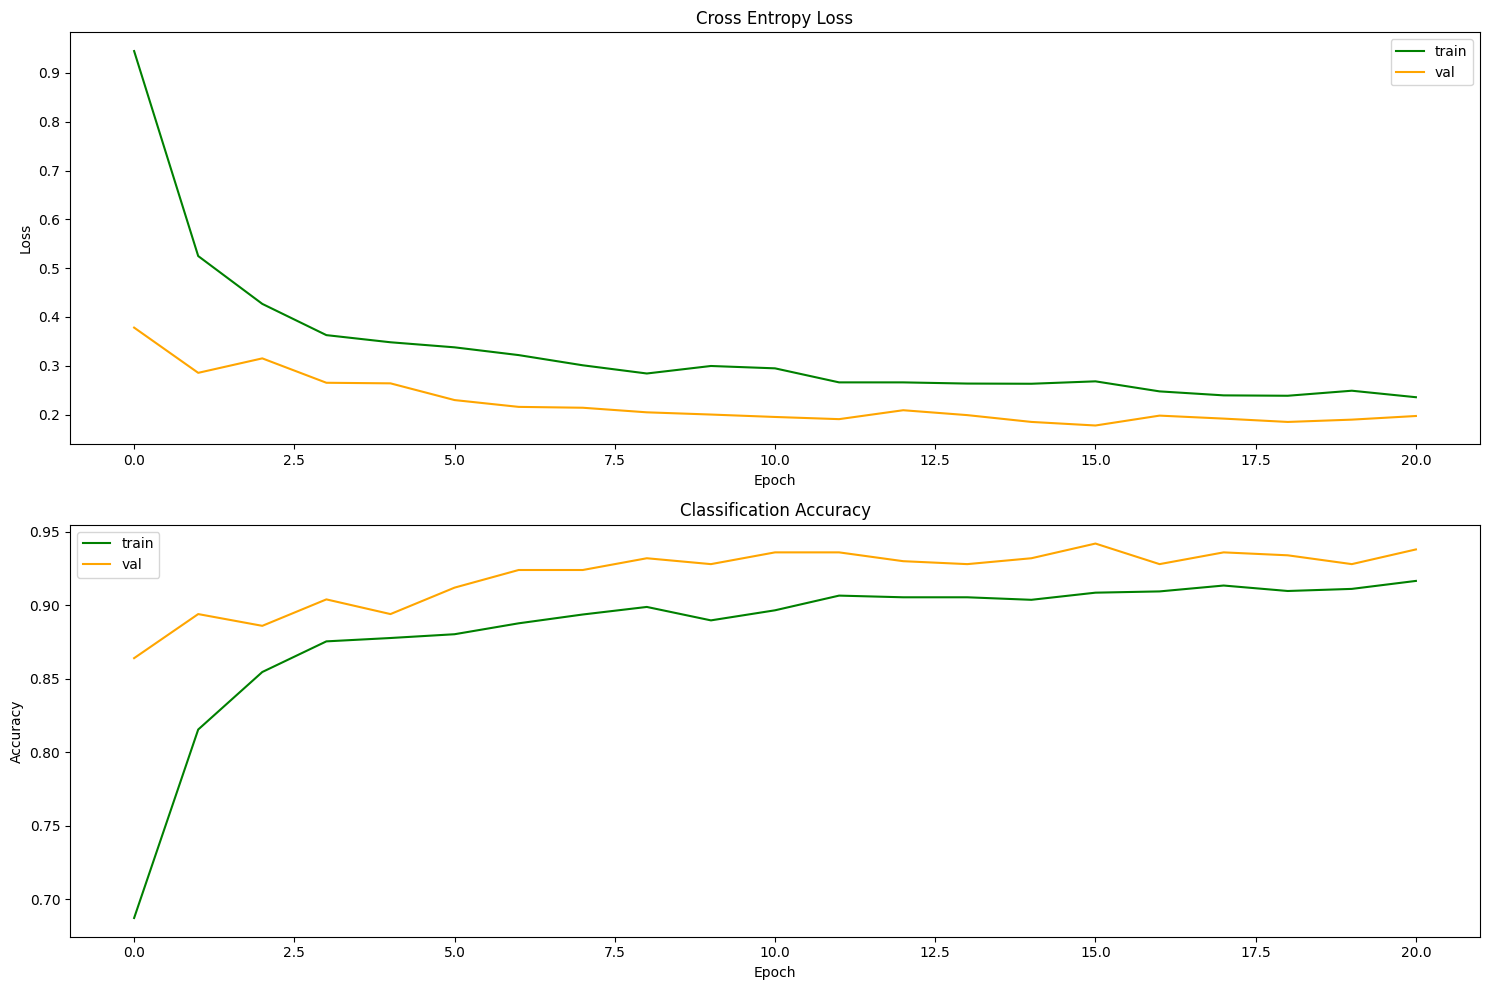

In [32]:
#Train and validation Loss
plt.figure(figsize=(15,10))
plt.subplot(211)
plt.title('Cross Entropy Loss')
plt.plot(history.history['loss'],color='green',label='train')
plt.plot(history.history['val_loss'],color='orange',label='val')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
#Train and validation accuracy
plt.subplot(212)
plt.title('Classification Accuracy')
plt.plot(history.history['accuracy'],color='green',label='train')
plt.plot(history.history['val_accuracy'],color='orange',label='val')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

### Evaluationg the model

32/32 ━━━━━━━━━━━━━━━━━━━━ 12s 222ms/step


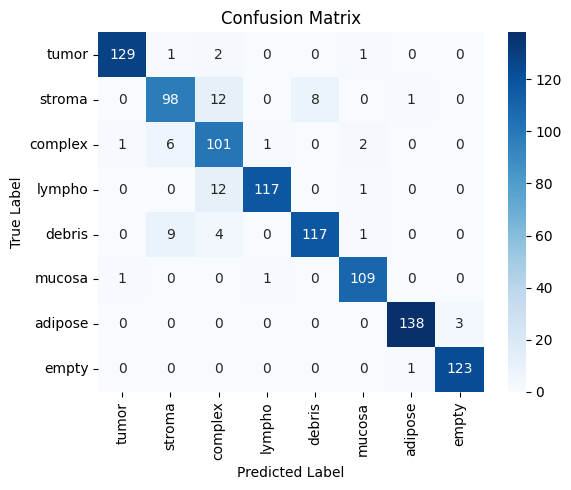

In [33]:
from sklearn.metrics import confusion_matrix

#Making the predictions on the test set:
predictions = model.predict(x_test) #generates a probability distribution across the 8 classes for each test image
predictions = np.argmax(predictions,axis=1) #selects the class with the highest predicted probability
gt = np.argmax(y_test,axis=1) #converts the one-hot encoded test labels back into their original numerical class labels.


#Confusion matrix
cm = confusion_matrix(gt,predictions)

#Visualization of the CM
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels,cbar=True)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

In [34]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

#Metrics
accuracy = accuracy_score(gt, predictions)
precision = precision_score(gt,predictions, average='weighted')
recall = recall_score(gt,predictions, average='weighted')
f1 = f1_score(gt,predictions, average='weighted')

print(f"Test accuracy:{accuracy:.2f}")
print(f"Test precision:{precision:.2f}")
print(f"Test recall:{recall:.2f}")
print(f"Test f1 score:{f1:.2f}")

Test accuracy:0.93
Test precision:0.94
Test recall:0.93
Test f1 score:0.93


In [ ]:
#Downloading the model
save_dir = os.path.join('model', 'resnet50_colorectal_histology.keras')
model.save(save_dir)
print(f'Model saved to {save_dir}')

NameError: name 'model' is not defined